<a href="https://colab.research.google.com/github/rashidsohaib10232/Front-end-battle/blob/main/h02-end-to-end/housing-transforms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

url = "https://github.com/ageron/data/raw/main/housing/housing.csv"

housing = pd.read_csv(url)
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


# TRAIN TEST SPLIT

In [2]:
from sklearn.model_selection import train_test_split

X = housing.drop('median_house_value', axis = 1)
y = housing

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)



In [3]:
print(X_train.shape, X_test.shape)
print(X_train.isnull().sum())

(16512, 9) (4128, 9)
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        163
population              0
households              0
median_income           0
ocean_proximity         0
dtype: int64


# SIMPLE IMPUTER

In [4]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy = 'median')

X_train[['total_bedrooms']] = imputer.fit_transform(X_train[['total_bedrooms']])
X_test[['total_bedrooms']] = imputer.transform(X_test[['total_bedrooms']])


In [5]:
print(X_train["total_bedrooms"].isnull().sum(), X_test["total_bedrooms"].isnull().sum())

0 0


# Plot

In [6]:
import matplotlib.pyplot as plt

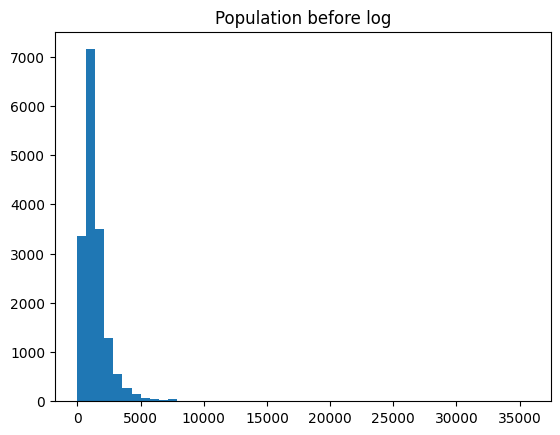

In [7]:
plt.hist(X_train['population'], bins =50)
plt.title('Population before log')
plt.show()    # long right tail

# Log Transformation

In [8]:
X_train['population_log'] = np.log1p(X_train['population'])
X_test['population_log'] = np.log1p(X_test['population'])

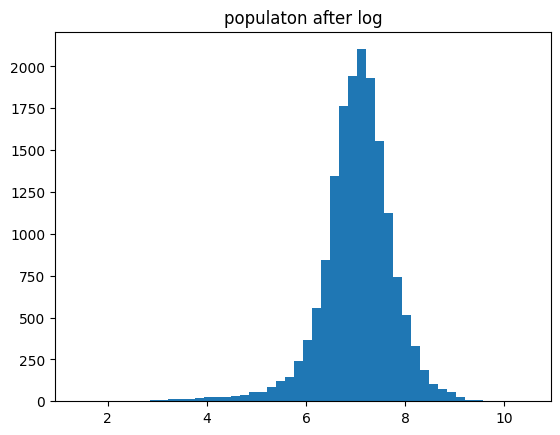

In [9]:
plt.hist(X_train['population_log'], bins=50)
plt.title("populaton after log")
plt.show()

# PowerTransformer

In [10]:
from sklearn.preprocessing import PowerTransformer

In [11]:
pt = PowerTransformer(method ='yeo-johnson')
X_train['population_pt'] = pt.fit_transform(X_train[['population']])
X_test["population_pt"] = pt.transform(X_test[["population"]])

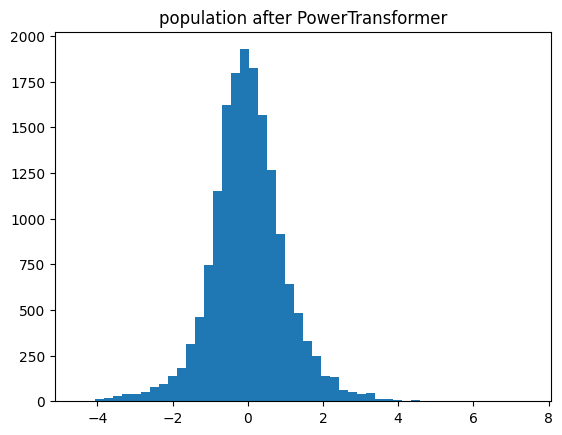

In [12]:
plt.hist(X_train['population_pt'], bins =50)
plt.title("population after PowerTransformer")
plt.show()

# MinMax

In [13]:
print(X_train["median_income"].describe())

count    16512.000000
mean         3.863585
std          1.907402
min          0.499900
25%          2.561150
50%          3.524600
75%          4.727000
max         15.000100
Name: median_income, dtype: float64


In [14]:
from sklearn.preprocessing import MinMaxScaler

In [15]:
mn = MinMaxScaler()

X_train[['median_income_mn']] = mn.fit_transform(X_train[['median_income']])
X_test[['median_income_mn']] = mn.transform(X_test[['median_income']])

In [16]:
X_train['median_income_mn'].min(), X_train['median_income_mn'].max()

(0.0, 1.0)

In [17]:
X_test['median_income_mn'].describe()

,median_income_mn
count,4128.000000
mean,0.234418
std,0.128905
min,0.000000
25%,0.143358
50%,0.212421
75%,0.298063
max,1.000000


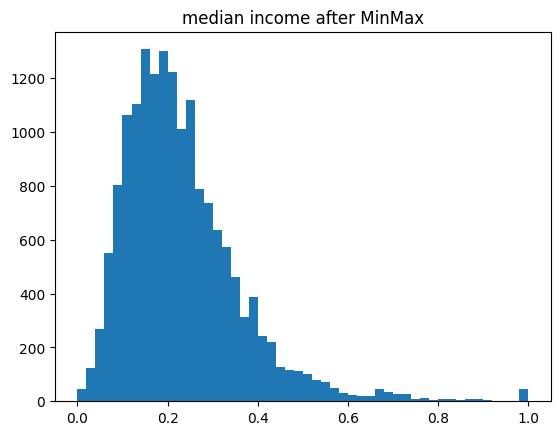

In [18]:
plt.hist(X_train['median_income_mn'],bins=50)
plt.title("median income after MinMax")
plt.show()

# RBF

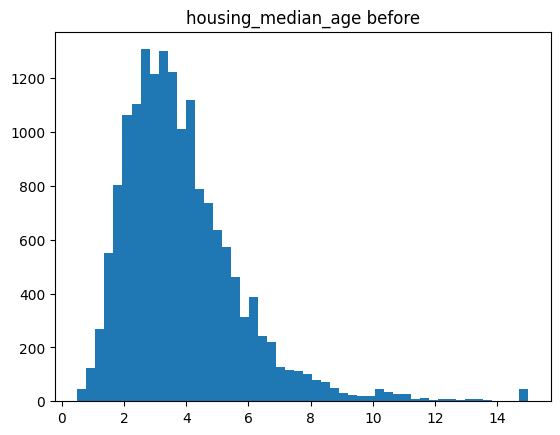

In [19]:
plt.hist(X_train['median_income'], bins = 50)
plt.title("housing_median_age before")
plt.show()

In [20]:
from sklearn.metrics.pairwise import rbf_kernel

In [21]:
X_train['age_simil_35'] = rbf_kernel(X_train[['housing_median_age']],[[35]], gamma = 1)

In [22]:
X_test["age_simil_35"] = rbf_kernel(X_test[['housing_median_age']],[[35]], gamma=1)

In [23]:
print(X_train[["housing_median_age", "age_simil_35"]].head(10))

       housing_median_age   age_simil_35
14196                34.0   3.678794e-01
8267                 10.0  3.680856e-272
17445                28.0   5.242886e-22
14265                25.0   3.720076e-44
2271                  8.0  2.507972e-317
17848                52.0  3.082441e-126
6252                 25.0   3.720076e-44
9389                 32.0   1.234098e-04
6113                 24.0   2.820770e-53
6061                 23.0   2.894640e-63


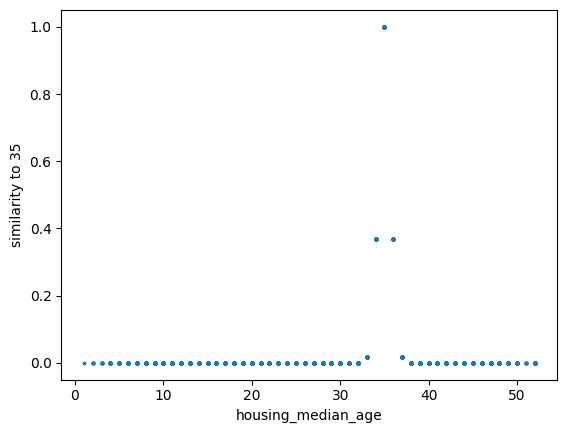

In [24]:
plt.scatter(X_train["housing_median_age"], X_train["age_simil_35"], s=2)
plt.xlabel("housing_median_age")
plt.ylabel("similarity to 35")
plt.show()